### Content
- Training Decision Tree
- Overfitting & Underfitting
- meshgrid function

In [2]:
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

In [3]:
iris = load_iris()

In [4]:
X, y = iris.data, iris.target

In [73]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2)

In [74]:
clf = DecisionTreeClassifier(criterion = 'entropy')

In [75]:
clf.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy')

In [76]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, clf.predict(X_test))

0.8666666666666667

In [77]:
from sklearn.model_selection import cross_val_score
import numpy as np

np.mean(cross_val_score(clf, X, y, cv = 10))

np.float64(0.96)

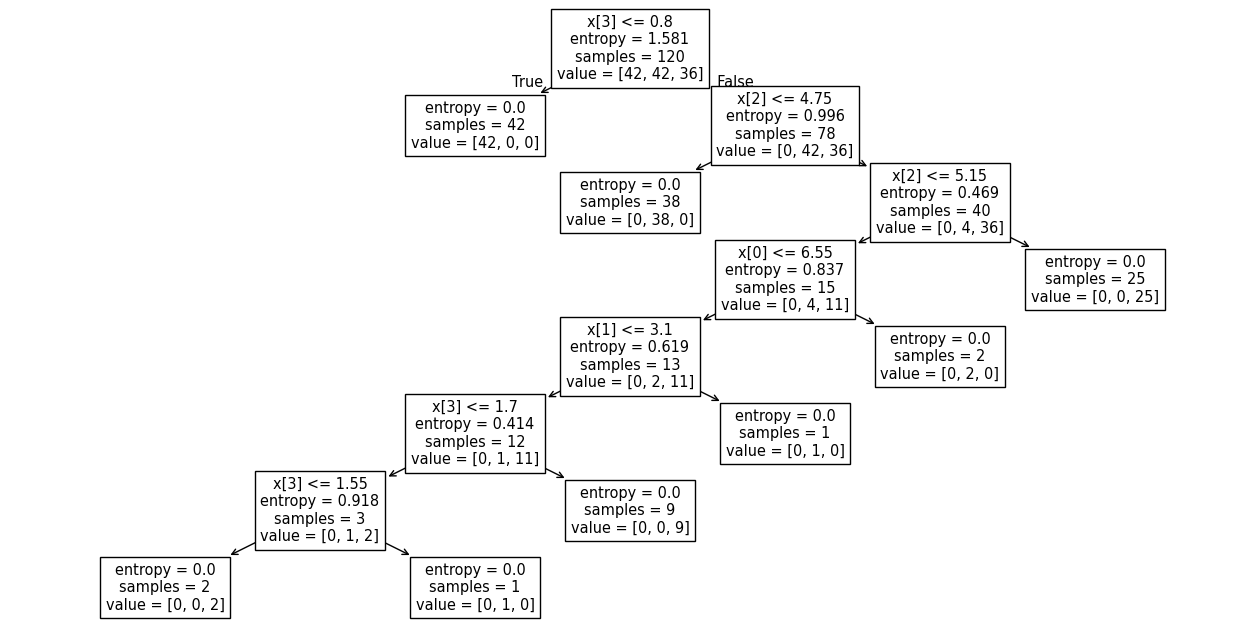

In [78]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize= (16,8))
plot_tree(clf)
plt.show()

In [79]:
# from sklearn.tree import export_graphviz

# export_graphviz(clf,
#                 out_file= 'iris_tree.dot',
#                 feature_names= iris.feature_names,
#                 class_names = iris.target_names,
#                 rounded = True,
#                 filled = True)

In [80]:
# from graphviz import Source

# Source.from_file('iris_tree.dot')

#### Overfitting & Underfitting in deision tree

In [89]:
def analyzer(max_depth):
    data = pd.read_csv('E:\\Data Science\\Machine Learning\\data\\Social_Network_Ads.csv')
    X = data.iloc[:,2:4].values
    y = data.iloc[:, -1].values

    clf = DecisionTreeClassifier(max_depth= max_depth)
    clf.fit(X,y)

    a = np.arange(start = X[:,0].min()-1, stop = X[:, 0].max()+1, step = 0.1)
    b = np.arange(start = X[:,1].min()-1, stop = X[:, 1].max()+1, step = 100)

    XX, YY = np.meshgrid(a,b)

    input_array = np.array([XX.ravel(), YY.ravel()]).T ## converted into 2 column n row shape for prediction.

    Z = clf.predict(input_array).reshape(XX.shape)

    plt.contourf(XX, YY, Z, alpha = 0.5)
    plt.scatter(X[:, 0], X[:, 1], c = y)

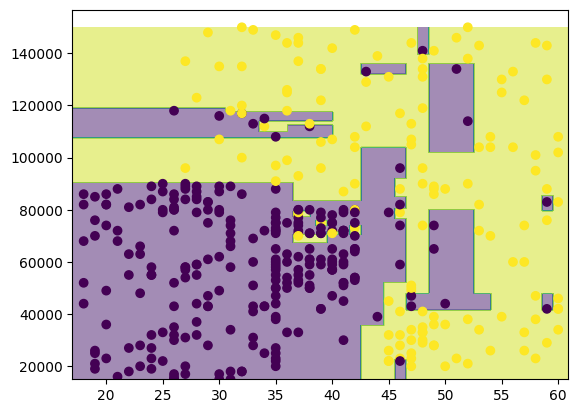

In [90]:
analyzer(max_depth= None)
### apprently visible overfitting. separates almost every points, which is not good.

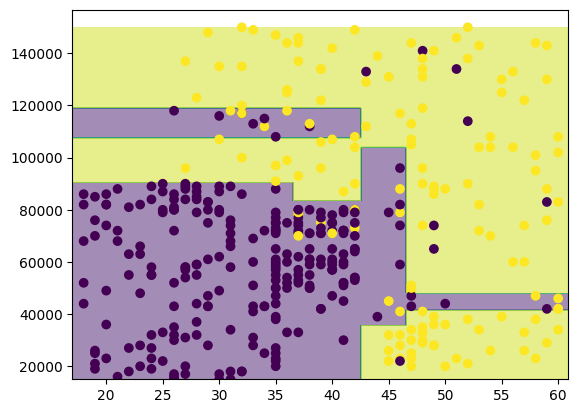

In [93]:
analyzer(max_depth = 4)

### Meshgrid function

##### With the help of meshgrid() function we can create 3D plots on 2D graphs. Meshgrid function converts 1D array to 2D arrays. In X it remains same on the column and different on the rows and vice verca for Y

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X = np.linspace(0,1, 20)
Y = np.linspace(0,2, 20)

In [83]:
XX, YY = np.meshgrid(X,Y)

In [84]:
# f = np.sin(4*XX) ** 2 + np.cos(YY)
f = 2*XX + YY**2

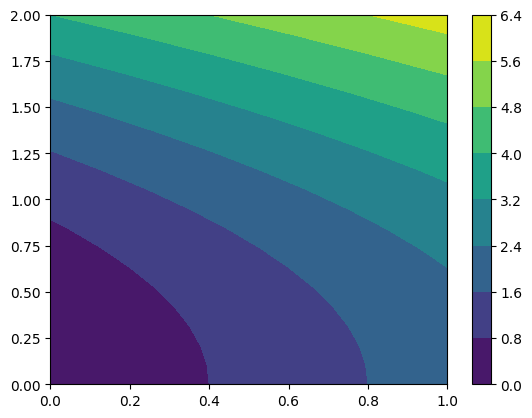

In [85]:
plt.contourf(XX,YY, f)
plt.colorbar()

In [86]:
f = (np.sin(XX)**2 + np.cos(YY)**3) / (3+np.sin(XX))

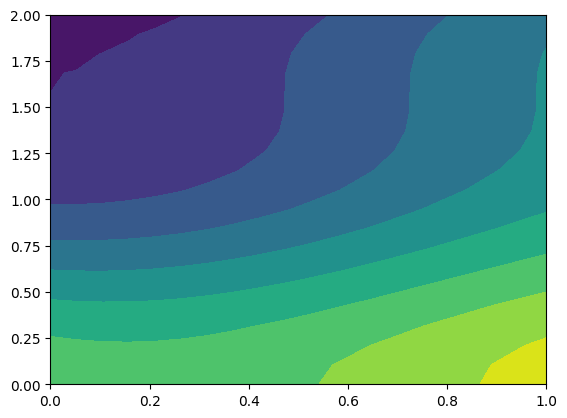

In [87]:
plt.contourf(XX,YY, f)